# Model History

The record of how the served model was reached, in order: v1, v2, the experiment loop, the Blend, Market Reach and its correction, the final round, and every read of 2023. The main notebook, [`exports_predictor.ipynb`](exports_predictor.ipynb), presents the served model; this one keeps the history it leaves out ([ADR 0013](../docs/adr/0013-the-product-shows-one-model-the-record-holds-the-history.md)).

Each chapter gives what was tried, the result and the decision, and links the ADR or research note that holds the detail. Tables and charts come from `exportspredictor.reporting.history`, read from three saved sources: the newest artefact (its earlier-version, v1-comparison and re-score blocks), the committed Test-year Ledger (and v2's gain ladder, committed once) and the experiment loop's saved results. Nothing is trained and no older artefact folder is opened. Results are associations on held-out data, not causes or forecasts.

## Parameters

`FIXTURE_MODE = True` (the default) runs on the fixture world in seconds, as `tests/test_notebook.py` does; parts only the real data holds then say they were not run. `scripts/rebuild.py --only history` sets it to False and reads the real sources.

In [1]:
import os

FIXTURE_MODE = True  # True: the tiny fixture world, in seconds. False: the real sources (reads saved results; trains nothing).

if os.environ.get("EXPORTSPREDICTOR_FIXTURE_MODE") == "0":
    FIXTURE_MODE = False  # scripts/rebuild.py sets this for the real run
# The committed outputs come from that real run, so the value below reads False although the default is True.
FIXTURE_MODE

False

In [2]:
import polars as pl

from exportspredictor import artefacts, comparison, loop, pipeline, reporting
from exportspredictor.evaluation import NOT_RUN
from exportspredictor.fixture import build_world
from exportspredictor.paths import artefacts_dir
from exportspredictor.reporting import history

In [3]:
if FIXTURE_MODE:
    world = build_world()
    bundle = pipeline.build_artefacts(
        world, source=pipeline.FIXTURE_SOURCE, parts=pipeline.Parts.every(), rescore=pipeline.fixture_rescore(world)
    )
    loop_results = bundle.metadata["ranking_experiments"]  # the fixture's own tiny loop
    probe = None  # the final round's probe ran on the real data only
else:
    bundle = artefacts.load_latest(artefacts_dir())  # the newest artefact; no older version's folder is opened
    loop_results = loop.ranking_record(loop.load())  # the experiment loop's saved results
    probe = history.final_round_probe()
report = comparison.relabelled(bundle.evaluation)  # the saved evaluation report, in today's words
print(reporting.provenance(bundle, lineage=False))

Outputs below come from artefact version 20261126T190421Z (source: BACI V202601; Model Form: Export Potential blends the model (weight 0.7) with the Naive Baseline (weight 0.3) on the log scale, then scales it by each Market's Market Reach, learned from the UK's other Products there in 2023).


## 1. v1

**Tried.** v1 was the first frozen version: one monotone-constrained Tweedie XGBoost model, every UK pair scored out-of-fold ([ADR 0001](../docs/adr/0001-out-of-fold-uk-training.md), [ADR 0002](../docs/adr/0002-single-xgboost-model-for-scenarios.md)). To fit 10 GB of VRAM it kept 30% of non-UK rows and 2% of Zero Cells ([ADR 0004](../docs/adr/0004-training-scope-and-sampling.md)). Its largest Export Gaps were crude oil, pipeline gas and gold, which led to the Excluded Products ([ADR 0005](../docs/adr/0005-product-exclusions-and-re-export-hubs.md)).

**Result.** It read 2023 once, on 17 November 2026. Its UK grid was frozen and checksummed, so later versions are compared with it without re-running it. Its row in the newest artefact, re-scored on the tie-proof measure (chapter 7):

In [4]:
history.earlier_versions(bundle, only="v1")

name,uk_ranking,uk_ranking_tie_proof,lift,size_matched_lift,tweedie_deviance_all_exporters,tweedie_deviance_uk,version
str,f64,f64,f64,f64,f64,f64,str
"""v1""",0.53969,0.53969,5.798361,0.833181,null,null,null


**Decision.** v1 became the bar for every later version: 0.540 on the 2023 UK ranking, against 0.514 for the Naive Baseline (*Course:* baselines first).

## 2. v2

**Tried.** v2 trained on more non-UK rows, added features and ran a hyperparameter search (Optuna TPE). Every choice was made on 2022 Tweedie deviance, with the UK ranking only as a guardrail, which passed at −0.0099 against a limit of −0.01 ([ADR 0002](../docs/adr/0002-single-xgboost-model-for-scenarios.md)). Of the three configurations the search confirmed, the winner had the lowest deviance and the lowest UK ranking (*Course:* the loss a model trains on can disagree with the metric people read):

In [5]:
reporting.search_confirmation(bundle)

trial,rounds,validation_deviance,uk_spearman
i64,i64,f64,f64
15,1198,364.253023,0.528035
23,1688,365.581411,0.530984
19,1829,365.841244,0.535824


On 2022, v2's configuration ranks the Markets the UK already serves better than the Naive Baseline (`non_zero_spearman`) but separates "any Flow" from "none" worse (`zero_vs_non_zero_spearman`). From the experiment loop's record:

In [6]:
history.zero_cells_against_naive(bundle)

model,selection_measure,non_zero_spearman,zero_vs_non_zero_spearman,tweedie_deviance
str,f64,f64,f64,f64
"""v2's configuration (seed 0)""",0.533391,0.525292,0.485796,371.6189
"""Naive Baseline""",0.547213,0.449941,0.509227,4331.893122


**Result.** On 2023 v2 ranked UK Markets at 0.511, below the Naive Baseline (0.514) and v1 (0.540), though its deviance over all Exporters, 356, was the lowest of any version. Under the comparison with v1 fixed before 2023 was read, v2 did not beat v1.

### The frozen results

These parts chose or checked v2 and decide nothing now ([ADR 0008](../docs/adr/0008-opportunity-ranking-is-the-one-objective.md)): the search above, the feature ablation, the learning curve, the v1 comparison, the gain ladder and the constraint comparison. The ablation, learning curve and constraint test stay in the main notebook as design evidence.

- **The gain ladder** climbed from v1 to v2 one group of changes at a time: v1's features and configuration on v2's training rows, then v2's features, then its tuning (*Course:* ablation run the other way). It associated almost all of v2's drop with the new training rows (−0.020 of −0.028), and about −0.004 each with the features and the tuning. It ran for v2 only, on artefact `20261118T100524Z`; on the real data the cell below draws it from a copy committed once, [`docs/gain-ladder-2023.json`](../docs/gain-ladder-2023.json), so no older artefact folder is opened.
- **The constraint comparison** (artefact `20261118T042154Z`): without the monotone constraint 39% of added agreements lowered Export Potential, and adding one moved Export Potential by +4.0% against +26.6% with it.

In [7]:
history.gain_ladder(bundle) if FIXTURE_MODE else history.saved_gain_ladder()

*The gain ladder: not run for this version.*

**Decision.** Choose on the ranking alone and report deviance beside it ([ADR 0008](../docs/adr/0008-opportunity-ranking-is-the-one-objective.md)): v2 was chosen on a measure that moved against the ranking, and the Naive Baseline knows something about whether trade happens at all that v2 lacked.

## 3. The experiment loop and every Arm

**Tried.** An experiment loop (`exportspredictor.loop`) re-chose the model under a rule fixed in code before any experiment was read ([ADR 0008](../docs/adr/0008-opportunity-ranking-is-the-one-objective.md), [research note](../docs/research/opportunity-ranking-experiments.md)):

- **Selection Measure**: the within-Product rank correlation for held-out UK pairs in 2022, averaged over Products.
- **Noise Floor**: v2's configuration with three seeds (*Course:* run-to-run noise).
- **Win Threshold**: twice the Noise Floor's standard deviation, at least 0.005. An Arm is kept only if it beats the best so far by more (*Course:* defensible selection, fixed in advance).

Arms ran on one seed against a cached base, so comparisons are paired, and none was added or re-run after its result was seen. Every Arm the newest artefact records before the final round (chapter 6):

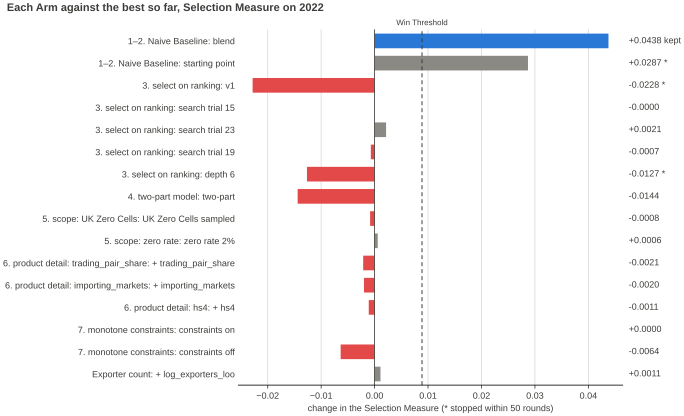

In [8]:
history.experiments_chart(bundle)

**Result.** Only the Blend cleared the Win Threshold; every later Arm before Market Reach landed within about +0.003 of it or below. Arms marked * reached their best round within their first 50 and stopped. Rounds stop on the model alone but Arms are judged on the Blend, so for these the stopping rule decided as much as the idea. The rule was kept: changing it after seeing results would have meant adding Arms mid-run.

### Ties cannot win

The open review of 2022 found that the Selection Measure could be won by saying less. Tied values took their average rank, and most UK Actual Exports are tied zeros. Flooring the Blend's Export Potential at $1,000 tied 52% of pairs with those zeros and lifted the measure from 0.5635 to 0.6062, as much as the Blend's whole win, with nothing ranked better.

Ties in Export Potential are now broken in a fixed pseudo-random order (`exportspredictor.selection_measure`), so tying can only lose: the same floor now lowers the measure to 0.5431, and the Blend's own score is unchanged to four places. Every past decision was re-checked under the fixed measure from cached models, and none flipped ([research note](../docs/research/loop-recheck-tie-proof-2022.md)). 2023 was not re-read for this.

**Decision.** Keep the Blend and drop every other Arm of the loop's first seven experiments.

## 4. The Blend

**Tried.** $$\text{Export Potential} = \exp\big(0.7\,\log \text{model} + 0.3\,\log \text{Naive Baseline}\big),$$ each side floored at $1, the weight chosen on the Selection Measure. The Naive Baseline orders Markets by whether trade is plausible at all, where v2 was weak; the model sizes the Markets the UK serves (*Course:* ensembles, a fixed weight chosen on validation data). [ADR 0008](../docs/adr/0008-opportunity-ranking-is-the-one-objective.md), *Outcome*.

### The five-fold confirmation

The Blend and v2 (the same fold model, alone) on all five folds of 2022, each fold model scoring only the UK pairs it held out, then over every pair (`all`; *Course:* k-fold cross-validation):

In [9]:
history.confirmation(bundle)

fold,winner,v2,difference,win_threshold
str,f64,f64,f64,f64
"""0""",0.577148,0.533391,0.043757,0.00887
"""1""",0.574481,0.52949,0.044992,0.00887
"""2""",0.575359,0.533813,0.041546,0.00887
"""3""",0.57387,0.528671,0.045198,0.00887
"""4""",0.574761,0.534845,0.039915,0.00887
"""all""",0.563464,0.520579,0.042885,0.00887


The Blend beats v2 on every fold, by 0.040 to 0.045, about five times the Win Threshold.

**Result on 2023.** The Blend read 2023 once, on 18 November: 0.555, above the Naive Baseline (0.514) and v1 (0.540), so the bar set in advance was met. Its deviance over all Exporters rose to 434 from v2's 356, as ADR 0008 expected. The pre-registered comparison with v1, run on the Blend without Market Reach, the form it was registered on:

In [10]:
v1_comparison = report.get("v1_comparison")
print(f"The v1 comparison: {NOT_RUN}." if v1_comparison is None else v1_comparison["verdict"]["text"])

This comparison scores the Blend without Market Reach, the form it was pre-registered on; the served form scales the Blend by each Market's Market Reach. The result is mixed, so it is reported metric by metric. Not met: no secondary metric gets worse beyond its own interval. On the UK out-of-fold within-Product rank correlation, the Blend's Export Potential ranks Markets in closer agreement with Actual Exports than v1's (0.554 against 0.540, a difference of +0.015, 95% interval +0.014 to +0.015); against the Naive Baseline (0.523) the margins are +0.031 for the Blend and +0.017 for v1. Tweedie deviance, all Exporters: v1 401.837, the Blend 435.213 (worse beyond its interval). RMSE of log(1 + value), all Exporters' non-zero Flows: v1 2.844, the Blend 2.695 (not worse beyond its interval). Size-matched Lift: v1 0.833, the Blend 0.765 (worse beyond its interval). Raw Lift (shown, not counted): v1 5.798, the Blend 5.044 (not counted). Event Backtest distance, EU exports to Japan, 2019: v1 

### The round count

The rule says deviance chooses nothing. The Blend's served models broke it in one place: they trained for v2's round count, which the search had early-stopped on Tweedie deviance, and the review found this only after 2023 was read. The next version took its rounds from the Selection Measure: the median of the five-fold confirmation's rounds (1,097), scaled to the fold models' rows (1,279). From the newest artefact:

In [11]:
history.round_count(bundle)

model,chosen_on,rounds_chosen,rounds_trained
str,str,i64,i64
"""served""","""Selection Measure""",1097,1279
"""next rebuild""","""Selection Measure""",1097,null


**Decision.** Serve the Blend, disclose the round count, and choose the next version's rounds on the Selection Measure.

## 5. Market Reach's first form and its correction

**Tried.** Market Reach scales the Blend by how widely the UK sends its Products to a Market against how widely the ranking expects, learned from other folds' pairs in the year before (*Course:* out-of-fold target encoding, applied to the Market; [ADR 0010](../docs/adr/0010-market-reach-in-the-model-form.md), [research note](../docs/research/market-reach-2022.md)). On 2022 it lifted the Selection Measure from 0.5635 to 0.6084, about five times the Win Threshold, so it was kept.

**The first form** counted every UK Flow as sent, whether or not the Market imported the Product from anyone else. Only the Falkland Islands, which reports no imports of its own, had more Products sent than imported (839 against 264), giving it a multiplier of about 230× and the fourth-largest Blocked Opportunity value. That form read 2023 on 20 November (fingerprint `a748777eac4b`): 0.600 on the tie-proof measure.

**The correction** counts as sent only the pairs the Market also imports. Re-checked on 2022 under the same procedure (β = 4 chosen again; ADR 0010, *Amendment*), it is a new Configuration Fingerprint, which read 2023 once on 26 November (chapter 7). What Market Reach changes on 2023, then what it cost in size:

In [12]:
print(reporting.market_reach_effect(bundle))
print(history.traded_away(bundle))

Market Reach is the change this version keeps. On 2023, the UK ranking is 0.603 with it against 0.554 without on the tie-proof Selection Measure (0.603 with it against 0.554 without on the old measure); on the 30 largest Markets 0.570 with it against 0.514 without; on the 60 largest Markets 0.604 with it against 0.543 without. Lift is 4.29 with it against 5.04 without (size-matched 0.75 against 0.77), each held-out Exporter scaled by its own Market Reach. The Potential Range holds 73% with it against 81% without of UK pairs' Gap Period Actual Exports. Market Reach leaves Scenario Effects unchanged, as it scales a pair's Export Potential with and without a Scenario alike. These are associations on one test year, not a forecast.
Choosing on the ranking traded away accuracy on size: Tweedie deviance over all Exporters is 469.8 for this version against 433.8 for Blend (lower is better), so the size of Export Potential is estimated less well. Size-matched Lift is 0.75 (Blend 0.76). Treat do

**Result.** The corrected form ranks UK Markets at 0.603 against the Naive Baseline's 0.514 and the Blend's 0.555, so nearly all the gain over the Blend is Market Reach. The cost is size: deviance over all Exporters is 470 against the Blend's 434, and on UK pairs 2,611 against 566.

**Decision.** Serve the Blend with corrected Market Reach, and say that the ranking deserves more trust than dollar values.

## 6. The final round's dropped ideas

**Tried.** First, the Exporter count, the 2022 error review's strongest candidate feature, as an Arm on rebuilt feature files: +0.0011 against a Win Threshold of 0.0089, dropped ([research note](../docs/research/exporter-count-2022.md)). Then, before shipping, a last round tried every remaining idea that needs only data already held ([research note](../docs/research/final-round-2022.md)). Each ran once on fold 0 of 2022 against the served form, under the same Win Threshold, after the artefact it was compared with was built. 2023 was not read. From the loop's saved results and the probe's saved file:

In [13]:
with pl.Config(fmt_str_lengths=70, tbl_cols=-1, tbl_width_chars=260):
    display(history.final_round(loop_results, probe))

idea,experiments,arms,best_arm,base,best,gain,threshold,judged_against,decision
str,i64,i64,str,f64,f64,f64,f64,str,str
"""Cap on Market Reach's upside (#163)""",1,1,"""cap Market Reach""",0.620987,0.620425,-0.000562,0.008869,"""Win Threshold""","""dropped"""
"""Sibling Demand as a feature (#164)""",1,1,"""+ log_sibling_demand_loo""",0.620966,0.621253,0.000286,0.008869,"""Win Threshold""","""dropped"""
"""A fresh hyperparameter search (#166)""",5,14,"""colsample_bytree 0.6""",0.620987,0.621469,0.000483,0.008869,"""Win Threshold""","""dropped"""
"""Other model families (#167)""",2,2,"""LightGBM""",0.620987,0.620534,-0.000452,0.008869,"""Win Threshold""","""dropped"""
"""A wider Exporter scope (#169)""",1,1,"""every Exporter""",0.621171,0.621194,0.000024,0.008869,"""Win Threshold""","""dropped"""
"""More rows through external memory (#170)""",1,1,"""non-UK rate 1.0, external memory""",0.620987,0.620942,-0.000044,0.008869,"""Win Threshold""","""dropped"""
"""Training on the Excluded Products (#171)""",1,1,"""train on the Excluded Products""",0.621417,0.620717,-0.0007,0.008869,"""Win Threshold""","""dropped"""
"""Tariff 0 where an agreement's preference is unrecorded (#171)""",0,0,"""scoring-only probe""",0.620987,0.620889,-0.000097,0.004435,"""its pre-registered gate""","""not retrained (missed its gate)"""


**Result.** Nothing was kept: the largest gain, +0.0005, is an eighteenth of the Win Threshold.

- Capping Market Reach's upside: slightly worse (*Course:* capping outliers).
- Sibling Demand, a demand proxy built from no UK Flow (*Course:* feature engineering).
- A hyperparameter search of 14 Arms (*Course:* grid search; tuning gains little over defaults).
- LightGBM and CatBoost, with the same monotone constraints (*Course:* gradient boosting, beyond the notes' one library).
- Every Exporter, or every row through GPU external memory (*Course:* learning curves: more data adds no signal the features lack). These two also close the gain ladder's open question: neither the Exporter scope nor the Excluded Products' rows explain v2's drop.
- Training on the Excluded Products (*Course:* sampling and weighting).
- A tariff of 0 where an agreement's preference is unrecorded: its scoring-only probe missed its pre-registered gate, so it was not retrained (*Course:* data cleaning).

**Decision.** The served form stands, with no new frozen version and no new read of 2023. All of this is association on one fold of one year.

## 7. Every read of 2023

2023 is read once per frozen version ([ADR 0009](../docs/adr/0009-test-year-read-once-per-frozen-version.md)): every choice is made on 2022 and fixed before 2023 is opened, and no 2023 result feeds back into that version (*Course:* look at the test set once). Each version's UK ranking on 2023, on the tie-proof measure; the earlier versions' figures re-score their saved 2023 scores:

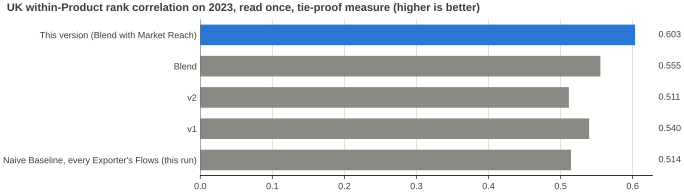

In [14]:
history.ranking_by_version(bundle)

Every figure behind the chart, on the old measure and the tie-proof one, with Lift and deviance. The two Naive Baseline rows come from slightly different Flows (every Exporter's rows, or v2's training rows):

In [15]:
history.earlier_versions(bundle)

name,uk_ranking,uk_ranking_tie_proof,lift,size_matched_lift,tweedie_deviance_all_exporters,tweedie_deviance_uk,version
str,f64,f64,f64,f64,f64,f64,str
"""This version (Blend with Marke…",0.603399,0.603399,4.291552,0.751761,469.771579,2610.84196,null
"""Blend""",0.555192,0.555192,4.993143,0.760532,433.764599,566.346004,"""20261118T185910Z"""
"""v2""",0.511496,0.511496,5.226938,0.787659,355.528809,568.588334,"""20261118T100524Z"""
"""v1""",0.53969,0.53969,5.798361,0.833181,null,null,null
"""Naive Baseline, every Exporter…",0.523115,0.514445,null,null,null,null,null
"""Naive Baseline as reported for…",0.523325,null,null,null,null,null,null


The same measure on the Markets that import the most, where Advisors usually look:

In [16]:
history.large_markets_by_version(bundle)

version,30 largest Markets,60 largest Markets
str,f64,f64
"""This version (Blend with Marke…",0.570002,0.604388
"""Blend""",0.51157,0.537386
"""v2""",0.537994,0.556363
"""v1""",0.509323,0.541787
"""Naive Baseline, every Exporter…",0.355354,0.395754


### The Test-year Ledger

Every read, from the committed ledger, oldest first. v1, v2, the Blend, Market Reach's first form and the corrected form each read 2023 once as an evaluation. Two runs re-scored the earlier versions' saved scores under the tie-proof measure (`re-score`), training and choosing nothing. The corrected form's run crashed after reading 2023 and before saving; the rerun used `--read-test-year-again`, no choice changed between them, and the ledger records why. Its re-score repeated the one already recorded and is marked as an override.

In [17]:
history.test_year_ledger()

date,version,fingerprint,read,command,override,kind,status
str,str,str,str,str,bool,str,str
"""2026-11-17""","""v1 (20261117T010658Z)""","""a77726cf17b0""","""test-year evaluation; the same…","""python -m exportspredictor.eva…",false,"""evaluation""","""completed"""
"""2026-11-18""","""v2 (20261118T042154Z)""","""f7cdd149f731""","""test-year evaluation; a throwa…","""python -m exportspredictor.pip…",false,"""evaluation""","""completed"""
"""2026-11-18""","""the Blend (20261118T185910Z)""","""f4d0be3058fd""","""test-year evaluation; Lift and…","""python -m exportspredictor.pip…",false,"""evaluation""","""completed"""
"""2026-11-20""","""20261120T221726Z""","""a748777eac4b""","""test-year evaluation; Lift and…","""python -m exportspredictor.pip…",false,"""evaluation""","""completed"""
"""2026-11-20""","""20261120T221726Z""","""5153ffef0c6a""","""re-scoring the saved test-year…","""python -m exportspredictor.pip…",false,"""re-score""","""completed"""
"""2026-11-26""","""20261126T190421Z""","""96f6f9164da1""","""test-year evaluation; Lift and…","""python -m exportspredictor.pip…",false,"""evaluation""","""completed"""
"""2026-11-26""","""20261126T190421Z""","""5153ffef0c6a""","""re-scoring the saved test-year…","""python -m exportspredictor.pip…",true,"""re-score""","""completed"""


**Decision.** The served form's own read is the headline: 0.603 against the Naive Baseline's 0.514 on the tie-proof measure. Every other read stays in this record and decides nothing about the served model.

## 8. Reproduce this record

The README's reproduction steps rebuild the product. These commands rebuild the history; each that reads 2023 is recorded in the Test-year Ledger, which refuses a fingerprint it has already read ([ADR 0009](../docs/adr/0009-test-year-read-once-per-frozen-version.md)).

- **The v1 comparison**: `python -m exportspredictor.pipeline compare` adds it, with its gain ladder, to a copy of the newest version, which must hold the Event Backtests.
- **The gain ladder** on a full build: `python -m exportspredictor.pipeline --gain-ladder` (or `--every-part`), about two more hours on the GPU.
- **The final round**: [`docs/research/final-round-2022.md`](../docs/research/final-round-2022.md) records each idea's command; the probe is `scripts/research/final_round_2022/unrecorded_preferences.py`.
- **This notebook's outputs**: `uv run python scripts/rebuild.py --only history`, which reads the three saved sources and trains nothing.